It is expected that the rocks would have a lower overall average echo energy and the metals would have a higher overall average echo energy because rocks are irregular and diffuse while metals are smooth and dense.



*   Null Hypothesis($H_0$): The difference in mean values of the echo energy between rocks and metals is just because of random error.
*   Alternate Hypothesis($H_a$): The difference in mean values of the echo energy between rocks and metals is real.



In [ ]:
!gdown --folder "https://drive.google.com/drive/folders/1pQgAoCjX3gChOctwFxXwceAdNnO3Y6ZW?usp=sharing"

Retrieving folder contents
Processing file 1E6QA1zuC8RrYyuE8beeqw3A_Wszue155 synthetic_echo_returns_400.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1E6QA1zuC8RrYyuE8beeqw3A_Wszue155
To: /content/Synthetic data/synthetic_echo_returns_400.csv
100% 438k/438k [00:00<00:00, 39.9MB/s]
Download completed


Critical t:   ±1.9679
95% CI for Difference: [0.1362, 0.1513]
Rock returns sample size:  200
Metal returns sample size: 200
t-statistic: 37.4805
p-value:     3.0905e-115


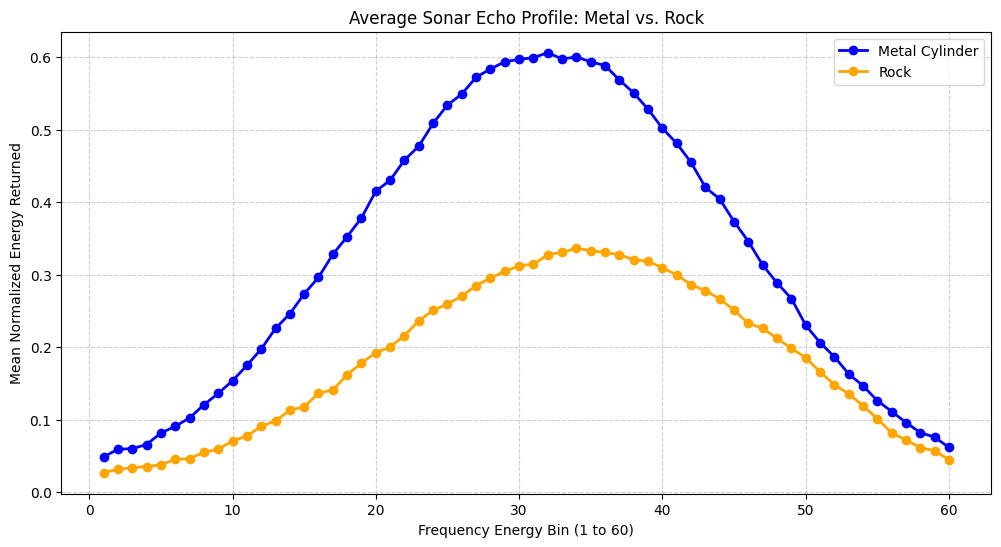

In [ ]:
#Starting with finding the mean values
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

# 1. Loading the CSV file
df = pd.read_csv('/content/Synthetic data/synthetic_echo_returns_400.csv')

# 2. Selecting the 60 energy bin columns (Columns index 2 through 61)
energy_bins = df.iloc[:, 2:62]
# 3. Calculating the horizontal mean across the 60 bins for EACH return (row)
df['row_mean'] = energy_bins.mean(axis=1)

# 4. Separate row means based on the class labels in the 'class' column
rock_means = df[df['class'] == 'rock']['row_mean']
metal_means = df[df['class'] == 'metal_cylinder']['row_mean']



#Running welsch t test

#finding the t_critical and 95% confidence interval

# 1. Degrees of freedom for Welch's test
s1_sq, s2_sq = metal_means.var(ddof=1), rock_means.var(ddof=1)
n1, n2 = len(metal_means), len(rock_means)
degf = ((s1_sq/n1 + s2_sq/n2)**2) / ((s1_sq/n1)**2/(n1-1) + (s2_sq/n2)**2/(n2-1))

# 2. Critical t-value for alpha = 0.05 (two-tailed)
t_crit = stats.t.ppf(1 - 0.05/2, degf)

# 3. 95% Confidence Interval for the difference in means (Metal - Rock)
diff = metal_means.mean() - rock_means.mean()
se = (s1_sq/n1 + s2_sq/n2)**0.5
ci_lower = diff - (t_crit * se)
ci_upper = diff + (t_crit * se)

print(f"Critical t:   ±{t_crit:.4f}")
print(f"95% CI for Difference: [{ci_lower:.4f}, {ci_upper:.4f}]")

t_stat, p_value = stats.ttest_ind(metal_means, rock_means, equal_var=False)

# Display the results
print(f"Rock returns sample size:  {len(rock_means)}")
print(f"Metal returns sample size: {len(metal_means)}")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_value:.4e}")
# Plotting energy bins vs average
# Group by 'class' and compute means for columns 2 to 61 (energy_bin_01 to energy_bin_60)
bin_means = df.groupby('class')[df.columns[2:62]].mean()

# Plot using the row labels directly
plt.figure(figsize=(12, 6))
plt.plot(range(1, 61), bin_means.loc['metal_cylinder'], '-o', label='Metal Cylinder', color='blue', linewidth=2)
plt.plot(range(1, 61), bin_means.loc['rock'], '-o', label='Rock', color='orange', linewidth=2)

plt.title('Average Sonar Echo Profile: Metal vs. Rock')
plt.xlabel('Frequency Energy Bin (1 to 60)')
plt.ylabel('Mean Normalized Energy Returned')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("my_plot.png", dpi=300, bbox_inches="tight")
plt.show()

Since the t value we found is much much greater than the critical t we can reject the null hypothesis succesfully and say that the difference in the mean is real and not just due to random error. Also